# Práctica 4 · Detección y seguimiento de personas y vehículos + matrículas

**Extras elegidos:** (1) comparar YOLO vs RT-DETR para detectar matrículas, (2) detección de matrículas con técnicas basadas en contornos.

Versión para **ejecución local** (entorno conda `VC_P4`; con GPU NVIDIA y CUDA va mucho más rápido).

Índice:
1. Instalación y datos
2. Conversión de anotaciones a formato YOLO + reparto train/val/test
3. Entrenamiento YOLO
4. Entrenamiento RT-DETR
5. Comparativa YOLO vs RT-DETR
6. Matrículas con contornos (OpenCV) y comparativa
7. Pipeline sobre el vídeo de test (tracking, conteo, vídeo y CSV)

## 1. Instalación y datos

In [1]:
%pip -q install ultralytics lapx tensorboard faster_coco_eval

Note: you may need to restart the kernel to use updated packages.


In [5]:
import os, torch

# ====== AJUSTA ESTAS RUTAS (usa r'...' si estás en Windows) ======
IMG_DIR = r'C:\Users\traco\UNIVERSIDAD\VC\P4\images'
ANN_DIR = r'C:\Users\traco\UNIVERSIDAD\VC\P4\annotations'
VIDEO   = r'C:\Users\traco\UNIVERSIDAD\VC\P4\C0142.mp4'
OUT_DIR = r'C:\Users\traco\UNIVERSIDAD\VC\P4\resultados'    # runs, vídeo y csv
# =================================================================

os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', DEVICE)
print(len(os.listdir(IMG_DIR)), 'archivos en fotos |', len(os.listdir(ANN_DIR)), 'archivos en annotations')
print(os.listdir(ANN_DIR)[:5])


Dispositivo: 0
2387 archivos en fotos | 2418 archivos en annotations
['00000.json', '00001.json', '00002.json', '00003.json', '0173FVB-cgg.json']


In [2]:
import os, torch, cv2, random, json
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO, RTDETR

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
EPOCHS, IMGSZ = 50, 640
RUNS = f'{OUT_DIR}/runs'
DATASET = os.path.join(OUT_DIR, 'dataset')
YAML = f'{DATASET}/plates.yaml'
print(DEVICE, os.path.exists(YAML), os.path.exists(f'{RUNS}/yolo11n_plates/weights/best.pt'))

0 True True


## 2. Anotaciones → formato YOLO + reparto

El conversor detecta automáticamente el formato (Pascal VOC `.xml`, YOLO `.txt`, COCO `.json` o labelme `.json`) y deja **una única clase: `plate`**.

In [8]:
import json, random, shutil, xml.etree.ElementTree as ET
from pathlib import Path
from PIL import Image

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
imgs = {p.stem: p for p in Path(IMG_DIR).rglob('*') if p.suffix.lower() in IMG_EXT}
print(len(imgs), 'imágenes encontradas')

def to_yolo(x1, y1, x2, y2, w, h):
    x1, x2 = sorted((x1, x2)); y1, y2 = sorted((y1, y2))
    return [(x1 + x2) / 2 / w, (y1 + y2) / 2 / h, (x2 - x1) / w, (y2 - y1) / h]

labels = {}  # stem -> lista de [cx, cy, w, h] normalizados
def add(stem, box):
    labels.setdefault(stem, []).append(box)

def img_size(stem):
    with Image.open(imgs[stem]) as im:
        return im.size  # (w, h)

ann_files = [p for p in Path(ANN_DIR).rglob('*') if p.is_file()]
print('Extensiones de anotación:', {p.suffix.lower() for p in ann_files})

for p in ann_files:
    e = p.suffix.lower()
    if e == '.xml':                                   # Pascal VOC
        r = ET.parse(p).getroot()
        fname = r.findtext('filename')
        stem = Path(fname).stem if fname else p.stem
        if stem not in imgs: stem = p.stem
        if stem not in imgs: continue
        w, h = img_size(stem)
        for o in r.findall('object'):
            b = o.find('bndbox')
            add(stem, to_yolo(float(b.findtext('xmin')), float(b.findtext('ymin')),
                              float(b.findtext('xmax')), float(b.findtext('ymax')), w, h))
    elif e == '.txt':                                 # ya en formato YOLO
        if p.stem not in imgs: continue
        for line in p.read_text().strip().splitlines():
            v = line.split()
            if len(v) >= 5: add(p.stem, [float(x) for x in v[1:5]])
    elif e == '.json':
        d = json.loads(p.read_text())
        if 'images' in d and 'annotations' in d:      # COCO
            id2img = {i['id']: i for i in d['images']}
            for a in d['annotations']:
                im = id2img[a['image_id']]; stem = Path(im['file_name']).stem
                if stem not in imgs: continue
                x, y, bw, bh = a['bbox']
                add(stem, to_yolo(x, y, x + bw, y + bh, im['width'], im['height']))
        elif 'shapes' in d:                           # labelme
            stem = Path(d.get('imagePath', p.name)).stem
            if stem not in imgs: stem = p.stem
            if stem not in imgs: continue
            w, h = d.get('imageWidth'), d.get('imageHeight')
            if not w: w, h = img_size(stem)
            for s in d['shapes']:
                xs = [pt[0] for pt in s['points']]; ys = [pt[1] for pt in s['points']]
                add(stem, to_yolo(min(xs), min(ys), max(xs), max(ys), w, h))
    else:
        print('Formato no soportado (revisar a mano):', p.name)

print(len(labels), 'imágenes con anotación,', sum(len(v) for v in labels.values()), 'matrículas')

2387 imágenes encontradas
Extensiones de anotación: {'.json'}
0 imágenes con anotación, 0 matrículas


In [9]:
RECT_MODE = 'center'   # 'topleft' (esquina sup. izquierda) o 'center'

labels, plate_txt, sin_imagen = {}, {}, 0
for p in Path(ANN_DIR).rglob('*.json'):
    stem = p.stem if p.stem in imgs else Path(p.stem).stem   # por si es "foto.jpg.json"
    if stem not in imgs:
        sin_imagen += 1
        continue
    data = json.loads(p.read_text(encoding='utf-8'))
    labels.setdefault(stem, [])          # imágenes sin matrícula = ejemplos negativos
    plate_txt.setdefault(stem, [])
    for o in data:
        a, b, w, h = o['rectangle']
        cx, cy = (a + w/2, b + h/2) if RECT_MODE == 'topleft' else (a, b)
        labels[stem].append([cx, cy, w, h])
        plate_txt[stem].append(o.get('plate'))

print(len(labels), 'imágenes con json,', sum(len(v) for v in labels.values()), 'matrículas')
print('JSON sin imagen asociada:', sin_imagen)

2387 imágenes con json, 5236 matrículas
JSON sin imagen asociada: 31


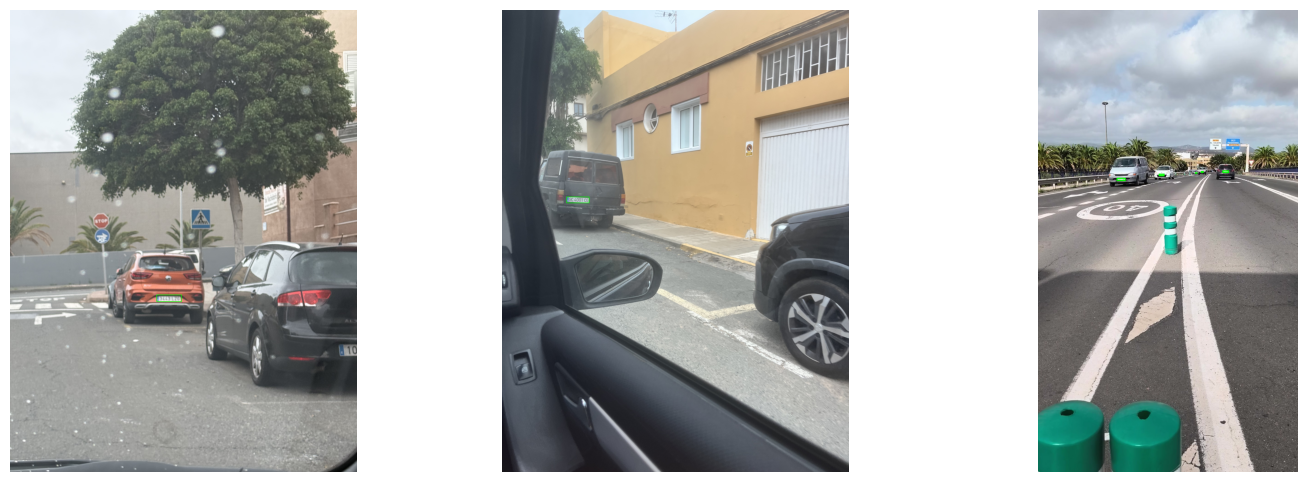

In [7]:
import cv2, matplotlib.pyplot as plt

muestra = random.sample([s for s in labels if labels[s]], 3)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a_, s in zip(ax, muestra):
    img = cv2.cvtColor(cv2.imread(str(imgs[s])), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    for cx, cy, w, h in labels[s]:
        cv2.rectangle(img, (int((cx-w/2)*W), int((cy-h/2)*H)),
                           (int((cx+w/2)*W), int((cy+h/2)*H)), (0, 255, 0), 4)
    a_.imshow(img); a_.axis('off')
plt.show()

In [10]:
random.seed(42)
stems = sorted(s for s in labels if s in imgs)
random.shuffle(stems)

n_test = int(0.2 * len(stems))
test = stems[:n_test]
rest = stems[n_test:]
n_val = int(0.1 * len(rest))
val, train = rest[:n_val], rest[n_val:]
splits = {'train': train, 'val': val, 'test': test}
print({k: len(v) for k, v in splits.items()})

DATASET = os.path.join(OUT_DIR, 'dataset')
shutil.rmtree(DATASET, ignore_errors=True)
for split, items in splits.items():
    os.makedirs(f'{DATASET}/{split}/images', exist_ok=True)
    os.makedirs(f'{DATASET}/{split}/labels', exist_ok=True)
    for s in items:
        shutil.copy(imgs[s], f'{DATASET}/{split}/images/{imgs[s].name}')
        with open(f'{DATASET}/{split}/labels/{s}.txt', 'w') as f:
            for b in labels[s]:
                f.write('0 ' + ' '.join(f'{x:.6f}' for x in b) + '\n')

YAML = f'{DATASET}/plates.yaml'
with open(YAML, 'w') as f:
    f.write(f"path: {DATASET}\ntrain: train/images\nval: val/images\ntest: test/images\nnc: 1\nnames: ['plate']\n")
print(open(YAML).read())

{'train': 1719, 'val': 191, 'test': 477}
path: C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset
train: train/images
val: val/images
test: test/images
nc: 1
names: ['plate']



## 3. Entrenamiento YOLO

In [3]:
from ultralytics import YOLO

IMGSZ = 640   # mantén el mismo valor que usaste en las primeras 50 épocas
yolo = YOLO(f'{RUNS}/yolo11n_plates/weights/last.pt')
yolo.train(data=YAML, epochs=50, imgsz=IMGSZ, batch=16, device=DEVICE,
           project=RUNS, name='yolo11n_plates_ext', exist_ok=False,
           patience=15, warmup_epochs=0)

Ultralytics 8.4.209  Python-3.9.5 torch-2.8.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset/plates.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\traco\UNIVERSIDAD\VC\P4\resultados/runs/yolo11n_plates/w

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000014041EF3820>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

## 4. Entrenamiento RT-DETR
Se usa la implementación de Ultralytics (mismo dataset y mismos hiperparámetros) para que la comparación sea justa. La implementación original de Baidu está en su GitHub (ver `VC_P4_RTDETR.ipynb` de la práctica).

In [4]:
rtdetr = RTDETR('rtdetr-l.pt')
rtdetr.train(data=YAML, epochs=EPOCHS, imgsz=IMGSZ, batch=8, device=DEVICE,
             project=RUNS, name='rtdetr_l_plates', exist_ok=True, patience=15)

Ultralytics 8.4.209  Python-3.9.5 torch-2.8.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset/plates.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtde

C:\Users\traco\anaconda3\envs\VC_P4\lib\site-packages\torch\autograd\graph.py:829: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:97.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/50      6.84G     0.9858      1.188     0.1712         29        640: 100% ━━━━━━━━━━━━ 215/215 1.7it/s 2:040.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.0s/it 35.9s0.3s9
                   all        191        401       0.83      0.631      0.643      0.341

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/50      7.39G     0.7951      0.469     0.1429         20        640: 0% ──────────── 0/215  0.7s

C:\Users\traco\anaconda3\envs\VC_P4\lib\site-packages\torch\autograd\graph.py:829: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:97.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/50      7.39G      0.856     0.4189     0.1169         11        640: 100% ━━━━━━━━━━━━ 215/215 2.2it/s 1:380.4sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.9it/s 3.1s0.3s
                   all        191        401      0.804      0.603      0.606      0.317

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/50      7.39G      1.147     0.3354     0.0973         17        640: 0% ──────────── 0/215  0.7s

C:\Users\traco\anaconda3\envs\VC_P4\lib\site-packages\torch\autograd\graph.py:829: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:97.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (92 outputs left out)

      49/50       7.3G     0.5144      0.374    0.09511         13        640: 100% ━━━━━━━━━━━━ 215/215 2.2it/s 1:370.4sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 4.0it/s 3.0s0.3s
                   all        191        401      0.906      0.741      0.763      0.446

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      50/50      7.41G      0.351     0.3685    0.02168         15        640: 0% ──────────── 0/215  0.6s

C:\Users\traco\anaconda3\envs\VC_P4\lib\site-packages\torch\autograd\graph.py:829: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:97.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      50/50      7.41G     0.5092     0.3744    0.09179         10        640: 100% ━━━━━━━━━━━━ 215/215 2.2it/s 1:370.4sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.9it/s 3.0s0.3s
                   all        191        401      0.896      0.751       0.76      0.443

50 epochs completed in 1.447 hours.
Optimizer stripped from C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\runs\rtdetr_l_plates\weights\last.pt, 66.2MB
Optimizer stripped from C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\runs\rtdetr_l_plates\weights\best.pt, 66.2MB

Validating C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\runs\rtdetr_l_plates\weights\best.pt...
Ultralytics 8.4.209  Python-3.9.5 torch-2.8.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001403430B100>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

## 5. Comparativa YOLO vs RT-DETR
### 5.1 Curvas de entrenamiento

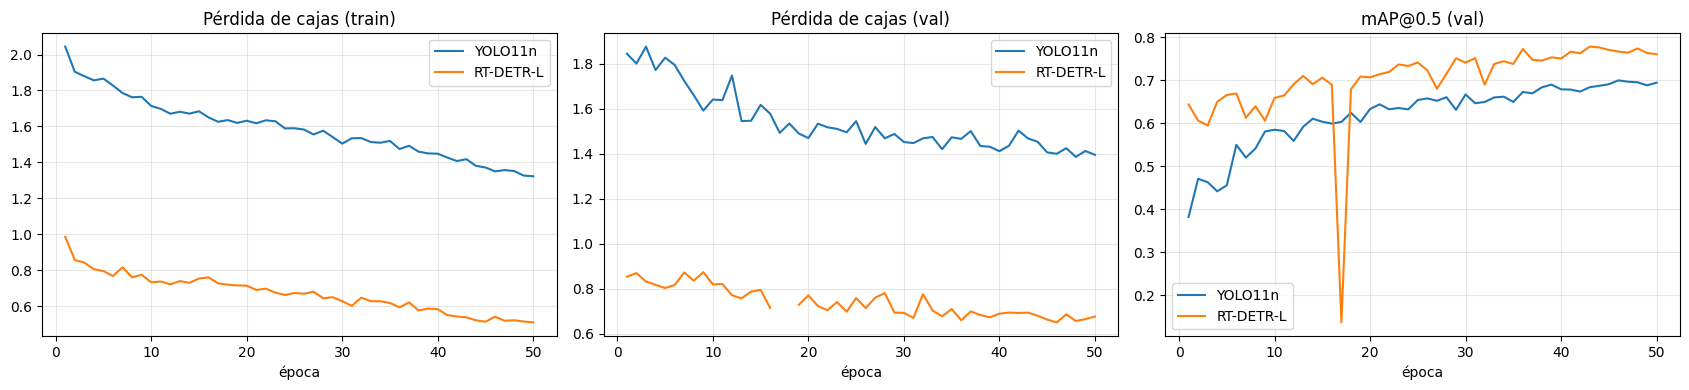

In [5]:
import pandas as pd, matplotlib.pyplot as plt

def load_results(name):
    df = pd.read_csv(f'{RUNS}/{name}/results.csv')
    df.columns = [c.strip() for c in df.columns]
    return df

runs = {'YOLO11n': 'yolo11n_plates', 'RT-DETR-L': 'rtdetr_l_plates'}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for label, name in runs.items():
    df = load_results(name)
    tcol = 'train/box_loss' if 'train/box_loss' in df else 'train/giou_loss'
    vcol = 'val/box_loss' if 'val/box_loss' in df else 'val/giou_loss'
    ax[0].plot(df['epoch'], df[tcol], label=label)
    ax[1].plot(df['epoch'], df[vcol], label=label)
    ax[2].plot(df['epoch'], df['metrics/mAP50(B)'], label=label)
for a, t in zip(ax, ['Pérdida de cajas (train)', 'Pérdida de cajas (val)', 'mAP@0.5 (val)']):
    a.set_title(t); a.set_xlabel('época'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 5.2 Métricas sobre el conjunto de test

In [3]:
def eval_model(model, name):
    r = model.val(data=YAML, split='test', imgsz=IMGSZ, device=DEVICE, verbose=False)
    return dict(modelo=name, precision=r.box.mp, recall=r.box.mr, mAP50=r.box.map50,
                mAP50_95=r.box.map, ms_por_imagen=r.speed['inference'])

best_yolo   = YOLO(f'{RUNS}/yolo11n_plates/weights/best.pt')
best_rtdetr = RTDETR(f'{RUNS}/rtdetr_l_plates/weights/best.pt')

tabla = pd.DataFrame([eval_model(best_yolo, 'YOLO11n'), eval_model(best_rtdetr, 'RT-DETR-L')]).set_index('modelo')
tabla.round(4)

Ultralytics 8.4.209  Python-3.9.5 torch-2.8.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2067.0±792.4 MB/s, size: 10488.0 KB)
val: Scanning C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset\test\labels.cache... 477 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 477/477  0.0s
val: C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset\test\images\20261031_174251.jpg: corrupt JPEG restored and saved
val: C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset\test\images\20261031_190622.jpg: corrupt JPEG restored and saved
val: C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset\test\images\20261031_190739.jpg: corrupt JPEG restored and saved
val: C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset\test\images\20261031_190852.jpg: corrupt JPEG restored and saved
val: C:\Users\traco\UNIVERSIDAD\VC\P4\resultados\dataset\test\images\20261031_191

,precision,recall,mAP50,mAP50_95,ms_por_imagen
modelo,,,,,
YOLO11n,0.9003,0.6048,0.6228,0.3405,3.9297
RT-DETR-L,0.8594,0.7029,0.6970,0.3955,22.8070


## 6. Matrículas con contornos (OpenCV)

Pipeline clásico: escala de grises → filtro bilateral → Canny → contornos → aproximación poligonal (4 vértices) → filtro por área y relación de aspecto (las matrículas españolas miden 520×110 mm, ratio ≈ 4.7).

In [4]:
import cv2, numpy as np

def detect_plates_contours(img, min_area_frac=0.0005, ar_range=(2.0, 6.5), max_cands=30):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.bilateralFilter(gray, 11, 17, 17)
    edges = cv2.dilate(cv2.Canny(gray, 30, 200), None, iterations=1)
    cnts, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    H, W = gray.shape
    out = []
    for c in sorted(cnts, key=cv2.contourArea, reverse=True)[:max_cands]:
        approx = cv2.approxPolyDP(c, 0.018 * cv2.arcLength(c, True), True)
        if len(approx) != 4: continue
        x, y, w, h = cv2.boundingRect(approx)
        if w * h < min_area_frac * W * H: continue
        if ar_range[0] <= w / float(h) <= ar_range[1]:
            out.append((x, y, x + w, y + h))
    return out

def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0

def load_gt(split, stem, w, h):
    boxes = []
    for line in open(f'{DATASET}/{split}/labels/{stem}.txt'):
        _, cx, cy, bw, bh = map(float, line.split())
        boxes.append(((cx - bw/2) * w, (cy - bh/2) * h, (cx + bw/2) * w, (cy + bh/2) * h))
    return boxes

def eval_detector(predict_fn, thr=0.5):
    tp = fp = fn = 0
    for p in Path(f'{DATASET}/test/images').iterdir():
        img = cv2.imread(str(p)); h, w = img.shape[:2]
        gts = load_gt('test', p.stem, w, h)
        preds = predict_fn(img)
        matched = set()
        for pr in preds:
            best, bj = 0, None
            for j, g in enumerate(gts):
                v = iou(pr, g)
                if v > best and j not in matched: best, bj = v, j
            if best >= thr: tp += 1; matched.add(bj)
            else: fp += 1
        fn += len(gts) - len(matched)
    P = tp / (tp + fp) if tp + fp else 0
    R = tp / (tp + fn) if tp + fn else 0
    return dict(precision=P, recall=R, F1=2*P*R/(P+R) if P+R else 0, TP=tp, FP=fp, FN=fn)

def pred_model(model):
    def f(img):
        r = model.predict(img, conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        return [tuple(b) for b in r.boxes.xyxy.cpu().numpy()]
    return f

comp = pd.DataFrame({
    'Contornos': eval_detector(detect_plates_contours),
    'YOLO11n':   eval_detector(pred_model(best_yolo)),
    'RT-DETR-L': eval_detector(pred_model(best_rtdetr)),
}).T
comp.round(3)

,precision,recall,F1,TP,FP,FN
Contornos,0.124,0.096,0.108,101.0,716.0,949.0
YOLO11n,0.874,0.623,0.727,654.0,94.0,396.0
RT-DETR-L,0.781,0.722,0.750,758.0,213.0,292.0


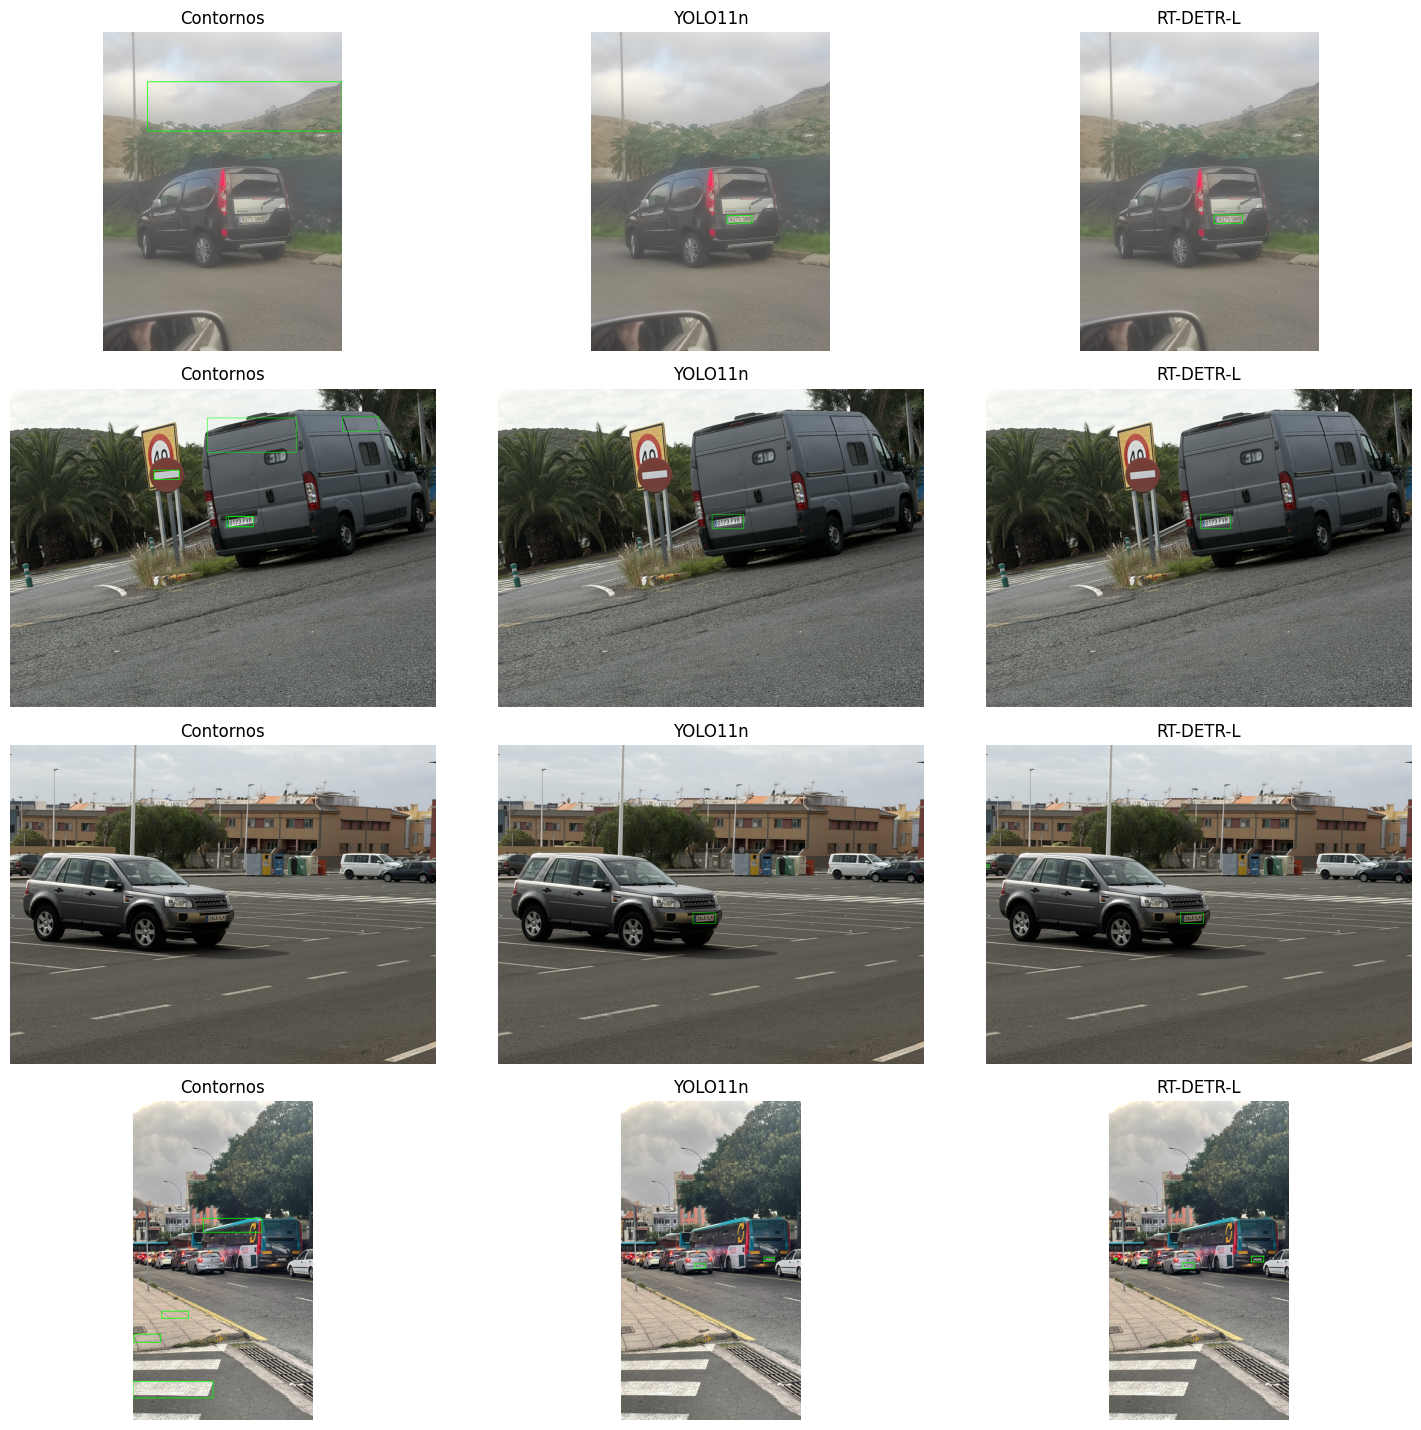

In [5]:
# Ejemplos visuales sobre imágenes de test
sample = sorted(Path(f'{DATASET}/test/images').iterdir())[:4]
fig, ax = plt.subplots(len(sample), 3, figsize=(15, 3.6 * len(sample)))
for i, p in enumerate(sample):
    img = cv2.imread(str(p))
    for j, (name, fn) in enumerate([('Contornos', detect_plates_contours), ('YOLO11n', pred_model(best_yolo)), ('RT-DETR-L', pred_model(best_rtdetr))]):
        vis = img.copy()
        for (x1, y1, x2, y2) in fn(img):
            cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 3)
        ax[i, j].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[i, j].set_title(name); ax[i, j].axis('off')
plt.tight_layout(); plt.show()

**Análisis (rellenar tras ejecutar):** comparar precisión/recall/velocidad, casos de fallo de los contornos (iluminación, fondos con muchos bordes rectangulares, perspectiva) y el compromiso precisión-velocidad entre YOLO y RT-DETR.

## 7. Pipeline completo sobre el vídeo de test

- Detección y seguimiento de personas y vehículos (YOLO11 + ByteTrack).
- Detección de matrícula dentro de cada vehículo (se elige el mejor modelo de la sección 5).
- Conteo de objetos únicos por clase, vídeo anotado y CSV.
- OCR opcional con EasyOCR (si no se instala, la columna `texto_matricula` queda vacía; se puede sustituir por el OCR de la práctica P4b).

In [6]:
%pip -q install easyocr

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Acceso denegado: 'C:\\Users\\traco\\anaconda3\\envs\\VC_P4\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.



In [11]:
import re
import numpy as np
from collections import Counter, defaultdict

CLASSES = {0: 'person', 2: 'car', 3: 'motorcycle', 5: 'bus', 7: 'truck'}
VEHICLES = {2, 3, 5, 7}

detector = YOLO('yolo11n.pt')
plate_model = best_rtdetr       # best_yolo si tarda demasiado (RT-DETR va unas 6 veces más lento)

try:
    import easyocr
    reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available())
except Exception as e:
    reader = None
    print('OCR no disponible:', e)

PROVINCES = {'A','AB','AL','AV','B','BA','BI','BU','C','CA','CC','CE','CO','CR','CS','CU','GC','GI','GR','GU',
             'H','HU','J','L','LE','LO','LU','M','MA','ML','MU','NA','O','OR','P','PM','PO','S','SA','SE','SG',
             'SO','SS','T','TE','TF','TO','V','VA','VI','Z','ZA'}
CONSONANTS = set('BCDFGHJKLMNPRSTVWXYZ')
TO_DIG = {'O':'0','Q':'0','D':'0','I':'1','L':'1','Z':'2','S':'5','G':'6','B':'8'}
TO_LET = {'0':'O','1':'I','2':'Z','5':'S','6':'G','8':'B'}
TEMPLATES = ['DDDDLLL', 'LDDDDL', 'LDDDDLL', 'LLDDDDL', 'LLDDDDLL']
ALLOW = '0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ'   # las matrículas antiguas usan todas las letras

def _coerce(chars, tpl):
    out, changes = [], 0
    for ch, t in zip(chars, tpl):
        if t == 'D':
            if ch.isdigit(): out.append(ch)
            elif ch in TO_DIG: out.append(TO_DIG[ch]); changes += 1
            else: return None, 0
        else:
            if ch.isalpha(): out.append(ch)
            elif ch in TO_LET: out.append(TO_LET[ch]); changes += 1
            else: return None, 0
    return ''.join(out), changes

def parse_plate(txt):
    txt = re.sub(r'[^A-Z0-9]', '', txt.upper())
    best = None
    for k, cand in enumerate((txt, txt[1:])):      # 2º intento: descarta la "E" de la banda azul
        for tpl in TEMPLATES:
            if len(cand) != len(tpl): continue
            s, ch = _coerce(cand, tpl)
            if s is None: continue
            if tpl == 'DDDDLLL':
                ok = all(c in CONSONANTS for c in s[4:])
            else:
                ok = s[:tpl.index('D')] in PROVINCES
            if ok and (best is None or ch + k < best[0]):
                best = (ch + k, s)
    return best[1] if best else ''
MIN_PLATE_W, PLATE_CONF, MAX_TRIES, MIN_FRAMES = 45, 0.40, 12, 15

def ocr_plate(crop):
    if reader is None or crop.size == 0: return '', 0.0
    g = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(g)
    res = reader.readtext(g, allowlist=ALLOW, detail=1)
    if not res: return '', 0.0
    txt = ''.join(t for _, t, _ in res).replace(' ', '').upper()
    return txt, float(np.mean([c for _, _, c in res]))

votes = defaultdict(lambda: defaultdict(float))   # tid -> texto -> suma de confianzas
tries = Counter()
def best_text(tid):
    return max(votes[tid], key=votes[tid].get) if votes[tid] else ''

OUT_VIDEO = f'{OUT_DIR}/resultado.mp4'
OUT_CSV   = f'{OUT_DIR}/resultado.csv'

cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS) or 25
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
writer = cv2.VideoWriter(OUT_VIDEO, cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))

rows, track_class, track_plate = [], {}, set()
frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok: break
    frame_idx += 1
    r = detector.track(frame, persist=True, classes=list(CLASSES), tracker='bytetrack.yaml',
                       conf=0.3, device=DEVICE, verbose=False)[0]
    if r.boxes is not None and r.boxes.id is not None:
        for (x1, y1, x2, y2), tid, c, cf in zip(r.boxes.xyxy.cpu().numpy().astype(int),
                                                r.boxes.id.int().cpu().tolist(),
                                                r.boxes.cls.int().cpu().tolist(),
                                                r.boxes.conf.cpu().tolist()):
            track_class[tid] = CLASSES[c]
            mrow = ['', '', '', '', '', '']
            if c in VEHICLES:
                ox, oy = max(x1, 0), max(y1, 0)
                crop = frame[oy:y2, ox:x2]
                if crop.size:
                    pr = plate_model.predict(crop, conf=0.25, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
                    if len(pr.boxes):
                        k = int(pr.boxes.conf.argmax()); pc = float(pr.boxes.conf[k])
                        if pc >= PLATE_CONF:
                            px1, py1, px2, py2 = pr.boxes.xyxy[k].cpu().numpy().astype(int)
                            mx1, my1, mx2, my2 = px1 + ox, py1 + oy, px2 + ox, py2 + oy
                            track_plate.add(tid)
                            if (mx2 - mx1) >= MIN_PLATE_W and tries[tid] < MAX_TRIES:
                                tries[tid] += 1
                                txt, oc = ocr_plate(frame[my1:my2, mx1:mx2])
                                norm = parse_plate(txt)
                                if norm: votes[tid][norm] += oc
                            mrow = [round(pc, 3), mx1, my1, mx2, my2, best_text(tid)]
                            cv2.rectangle(frame, (mx1, my1), (mx2, my2), (0, 0, 255), 2)
                            cv2.putText(frame, best_text(tid), (mx1, max(my1 - 5, 12)),
                                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
            rows.append([frame_idx, CLASSES[c], round(cf, 3), tid, x1, y1, x2, y2,
                         1 if mrow[0] != '' else 0] + mrow)
            color = (0, 255, 0) if c == 0 else (255, 128, 0)
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            cv2.putText(frame, f'{CLASSES[c]} #{tid}', (x1, max(y1 - 6, 12)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    txt_counts = ' | '.join(f'{k}: {v}' for k, v in Counter(track_class.values()).items())
    cv2.rectangle(frame, (0, 0), (W, 40), (0, 0, 0), -1)
    cv2.putText(frame, txt_counts, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    writer.write(frame)
cap.release(); writer.release()

cols = ['fotograma', 'tipo_objeto', 'confianza', 'identificador_tracking', 'x1', 'y1', 'x2', 'y2',
        'matricula_en_su_caso', 'confianza_matricula', 'mx1', 'my1', 'mx2', 'my2', 'texto_matricula']
df = pd.DataFrame(rows, columns=cols)

# texto final por vehículo (voto de todos los fotogramas) en todas sus filas con matrícula
final_text = {tid: best_text(tid) for tid in votes}
df['texto_matricula'] = np.where(df['matricula_en_su_caso'] == 1,
                                 df['identificador_tracking'].map(final_text).fillna(''), '')
df.to_csv(OUT_CSV, index=False)

frames_per_id = df.groupby('identificador_tracking').size()
estables = Counter(track_class[t] for t, n in frames_per_id.items() if n >= MIN_FRAMES)
print('Fotogramas procesados:', frame_idx)
print('Conteo bruto (ids únicos):', dict(Counter(track_class.values())))
print(f'Conteo estable (>= {MIN_FRAMES} fotogramas):', dict(estables))
print('Vehículos con matrícula detectada:', len(track_plate))
print('Con texto válido:', {t: v for t, v in final_text.items() if v})

Fotogramas procesados: 2832
Conteo bruto (ids únicos): {'car': 222, 'bus': 7, 'person': 38, 'truck': 7, 'motorcycle': 4}
Conteo estable (>= 15 fotogramas): {'car': 138, 'person': 18, 'motorcycle': 2, 'bus': 1}
Vehículos con matrícula detectada: 35
Con texto válido: {341: 'O0517M', 626: '1038WYV', 678: 'S1616I'}


In [10]:
df = pd.read_csv(OUT_CSV)
print(df.shape)
print(df.head(10).to_string())
print(df['tipo_objeto'].value_counts())
print(df[df['matricula_en_su_caso'] == 1][['fotograma','identificador_tracking','confianza_matricula','texto_matricula']].head(15).to_string())

cap = cv2.VideoCapture(OUT_VIDEO)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
for n in [total // 4, total // 2, 3 * total // 4]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, n)
    ok, f = cap.read()
    if ok:
        cv2.imwrite(f'{OUT_DIR}/frame_{n}.jpg', f)
cap.release()

(20941, 15)
   fotograma tipo_objeto  confianza  identificador_tracking    x1   y1    x2   y2  matricula_en_su_caso  confianza_matricula     mx1    my1     mx2    my2 texto_matricula
0          1         bus      0.936                       1  1402   52  1918  476                     1                0.568  1901.0  411.0  1918.0  429.0             NaN
1          1         car      0.844                       2  1321  312  1398  371                     0                  NaN     NaN    NaN     NaN    NaN             NaN
2          1         car      0.491                       3  1231  313  1279  343                     0                  NaN     NaN    NaN     NaN    NaN             NaN
3          1         car      0.349                       4  1281  318  1320  343                     0                  NaN     NaN    NaN     NaN    NaN             NaN
4          2         bus      0.933                       1  1407   56  1912  471                     1                0.592  1883.0 

## Entrega
- Subir este cuaderno, el README, el vídeo resultado (o enlace) y el CSV a GitHub.
- Incluir acceso al dataset (enlace a Drive) y el análisis del entrenamiento (curvas y métricas de las secciones 3-6).